# Example Notebook Showing How to Train Model
The MeteoHistorical class gives you the possiblility to access vast amounts of data, which can be used for your data-science project. Within this model, a custom WeatherPrediction class - a Neural Network - can be trained in order to predict the temperature of the following date. Not, I haven't really put any effort into refining this model - I've just thrown it together without much hyperparameter tuning just to give you an idea of how we can build a useful data science Python project - combining OOP principles and getting data from APIs in order to build your data science project. Note also that I'm not expecting any data science model in the OOP assignment, again, this project has been thrown together to show you OOP principles being applied to a data science project. 

First - just like before, we're going to want to collect the data needed to train our neural network. Luckily, thanks to the MeteoHistorical class, this will be really easy! Once again, let's use York as an example and collect data from all of this millenium:

In [1]:
from openmeteo_example import MeteoHistorical
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime as dt
import numpy as np

# Keep False unless you want to re-train the model
RETRAIN = True

# Define location
LOCATION = (53.3557, -1.6303)

# Instantiate object
weather_data = MeteoHistorical(*LOCATION)

# Get data from 2000 onwards
START_DATE = dt.datetime(2000, 1, 1)
END_DATE = dt.datetime(2025, 5, 1)

weather_data.get_data(START_DATE, END_DATE)

# Obviously, we can do simple stats on this data
york_temp = weather_data.temperature

temp_data = np.array(york_temp[1])
max_index = np.argmax(york_temp[1])
min_index = np.argmin(york_temp[1])
dtfmt = "%a %d %B %Y"

print(
    f"The average temperature in York this millenium is {temp_data.mean():.1f} ± {temp_data.std():.1f} °C"
)
print(
    f"The maximum temperature was {york_temp[1][max_index]:.1f} °C on {york_temp[0][max_index].strftime(dtfmt)}"
)
print(
    f"The minmum temperature was {york_temp[1][min_index]:.1f} °C on {york_temp[0][min_index].strftime(dtfmt)}"
)

The average temperature in York this millenium is 7.6 ± 5.5 °C
The maximum temperature was 32.2 °C on Tue 19 July 2022
The minmum temperature was -12.8 °C on Mon 06 December 2010


Now we have the data for last 25 years, we can use it to train our neural network. A basic model has been thrown together and can be imported from ```openmeteo_example.prediction```. It is a 4-layer neural network. We can feed it the MeteoHistorical object to pass in the data, and use the ```train_model``` function to optimise the parameters:

In [2]:
import torch
from openmeteo_example.prediction import WeatherPredictor, train_model

# Create predictor
predictor = WeatherPredictor(weather_data)

# Extract list of days that the data knows about - we'll avoid the first
# and last 10 days just to make sure we have enough data to make predictions
# Create list of days
days = predictor.weather.cloud[0][240:-240]
days = list({day.replace(hour=0, minute=0, second=0) for day in days})

# Split into training and testing (80% - 20%)
training_days, test_days = torch.utils.data.random_split(days, [0.8, 0.2])

Now we have split our data, let's train the model using the function. We'll train for 150 epochs:

  0%|          | 0/150 [00:00<?, ?it/s]

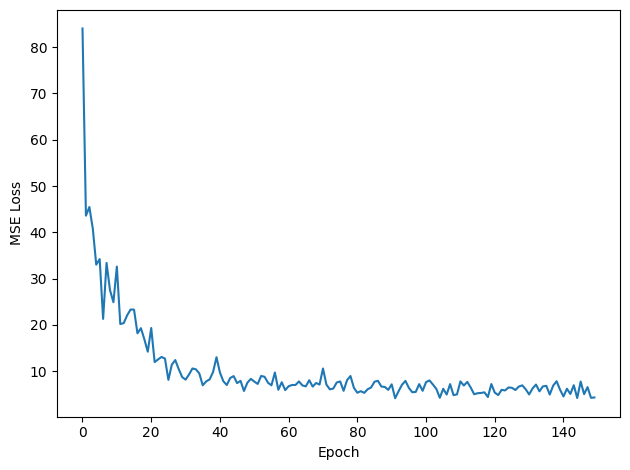

In [3]:
if RETRAIN:
    # Train model
    optimum_predictor, losses = train_model(
        training_days, model=predictor, n_epochs=150
    )

    # Looking at MSE Loss over time
    fig1, ax1 = plt.subplots()
    ax1.plot(losses)
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("MSE Loss")
    fig1.tight_layout()
else:
    predictor.load_model("Parameters.zip")
    optimum_predictor = predictor

We can now see how well the model performs on the test data that we held back to see how good the predictor model is:

In [4]:
# Actual values from labels
test_labels = torch.stack(
    [optimum_predictor._select_label_data(day) for day in test_days]
)

# Calculate predictors
test_predictions = torch.stack([optimum_predictor(day) for day in test_days])

# Calculate LSE loss
L = torch.nn.MSELoss()
test_loss = L(test_predictions, test_labels)

print(f"Loss in test data is {test_loss:.3f}")

Loss in test data is 6.000


We have a similar loss score for the test data compared to the training data, so we didn't overfit to the training data. Let's see how the predictions look on a time series graph. Let's compare our predictions to the actual weather on [15th July](https://www.historic-uk.com/CultureUK/St-Swithuns-Day/) 2010:

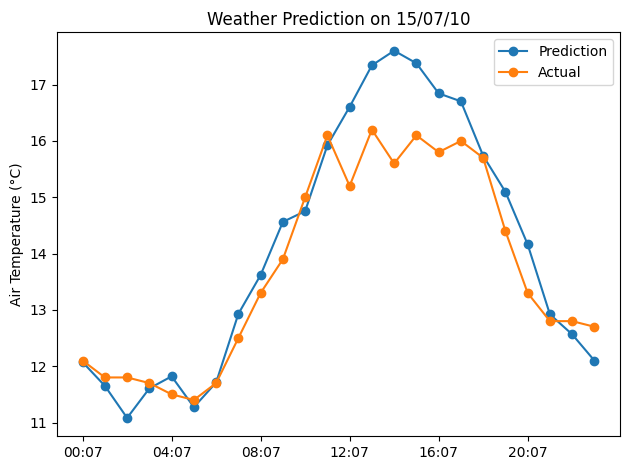

In [5]:
# Select date
april_date = dt.datetime(2010, 7, 15)
time_axis = april_date + dt.timedelta(hours=1) * np.arange(24)

prediction = optimum_predictor(april_date).detach().numpy()
actual_temp = optimum_predictor._select_label_data(april_date).detach().numpy()

# Plot Graph
fig2, ax2 = plt.subplots()
ax2.plot(time_axis, prediction, "-o", label="Prediction")
ax2.plot(time_axis, actual_temp, "-o", label="Actual")
ax2.set_ylabel("Air Temperature (°C)")

dtfmt = mdates.DateFormatter("%H:%m")
ax2.set_xticks(time_axis[::4])
ax2.xaxis.set_major_formatter(dtfmt)
ax2.set_title(f"Weather Prediction on {april_date.strftime('%d/%m/%y')}")
ax2.legend()
fig2.tight_layout()

optimum_predictor.save_model("Parameters.zip")

Obviously this is a very basic example, and the model - whilst being OK - will only really work for York. However, data-driven weather forecasting is becoming more and more of a thing - see this recent [Nature publication](https://www.nature.com/articles/s41586-025-08897-0) looking at replacing traditional weather forecasting, based on numerically solving the Navier-Stokes (differential) equations. Given that solutions to the Navier-Stokes equations exhibit chaotic behaviour, traditional weather forecasts tend to run multiple forward predictions with slight variations with a view to work out what the "average" of all of the iterations will be. Hence, traditional weather forecasting is extremely numerically expensive as you end up doing hundreds of weather forecasts in one!